In [206]:
from google.colab import drive
drive.mount('/content/drive')

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).


In [207]:
import tensorflow as tf
print(tf.__version__)

2.12.0


In [208]:
!pip install Keras-Preprocessing

In [209]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
%matplotlib inline
import seaborn as sns
import re,json,nltk
from sklearn.preprocessing import LabelEncoder
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.model_selection import train_test_split
import numpy as np
from keras.preprocessing.text import Tokenizer
from keras_preprocessing.sequence import pad_sequences
from keras.models import Sequential
from keras.layers import LSTM,Dense,Embedding,SpatialDropout1D
from keras.utils.np_utils import to_categorical
from sklearn.model_selection import train_test_split
from sklearn.metrics import  confusion_matrix
import seaborn
from sklearn.feature_extraction.text import CountVectorizer
import plotly as py
import cufflinks as cf
import tensorflow
from tensorflow.keras import Sequential
from plotly.offline import iplot
py.offline.init_notebook_mode(connected=True)
cf.go_offline()
from tensorflow.keras.layers import Bidirectional, GlobalMaxPool1D, Dense, LSTM, Conv1D, Embedding

In [210]:
file_path = '/content/drive/MyDrive/Bkash Fraud paper/Bkash Fraud Analysis.csv'

In [211]:
df = pd.read_csv(file_path,encoding='UTF-16',sep='\t')
df.head(3)

,Comments,Label
0,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে। ৫০০ ...,Fraud
1,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,Fraud
2,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,Fraud


In [212]:
### Stopwords Removal
'''
def process_conversations(Conversation):
    stp = open('/content/drive/MyDrive/ Sentiment Analysis/Code/stopwords-bn (1).txt','r',encoding="utf8").read().split()
    result = Conversation.split()
    Conversation = [word.strip() for word in result if word not in stp ]
    Conversation =" ".join(Conversation)
    Conversation = re.sub('[^\u0980-\u09FF]',' ',str(Conversation))
    return Conversation
'''

'\ndef process_conversations(Conversation):\n    stp = open(\'/content/drive/MyDrive/ Sentiment Analysis/Code/stopwords-bn (1).txt\',\'r\',encoding="utf8").read().split()\n    result = Conversation.split()\n    Conversation = [word.strip() for word in result if word not in stp ]\n    Conversation =" ".join(Conversation)\n    Conversation = re.sub(\'[^ঀ-\u09ff]\',\' \',str(Conversation))\n    return Conversation\n'

In [213]:
import re
def process_comments(Comments):
    Comments = re.sub('[^\u0980-\u09FF]',' ',str(Comments)) #removing unnecessary punctuation
    return Comments

In [214]:
# Apply the function into the dataframe
df['cleaned'] = df['Comments'].apply(process_comments)

# print some cleaned reviews from the dataset
sample_data = [13,17,23]
for i in sample_data:
     print('Original:\n',df.Comments[i],'\nCleaned:\n',
           df.cleaned[i],'\n','Lable:-- ',df.Label[i],'\n')

Original:
 এটা প্রথম না আমি বিকাশ এজেন্ট প্রতারিত হয়েছি ২০ সালে  তিন টাকা কম ৪০,০০০/= নিয়েছে এই চক্র  আপনাদের কাছে প্রথম হতে পারে আমাদের কাছে অনেক পুরানো 
Cleaned:
 এটা প্রথম না আমি বিকাশ এজেন্ট প্রতারিত হয়েছি ২০ সালে  তিন টাকা কম ৪০ ০০০   নিয়েছে এই চক্র  আপনাদের কাছে প্রথম হতে পারে আমাদের কাছে অনেক পুরানো 
 Lable:--  Partial Fraud 

Original:
 আমার আব্বুর বিকাশ থেকে গতকাল রাতে ৪০০০ হাজার একশত ৬০ টাকা নিয়েছে 
Cleaned:
 আমার আব্বুর বিকাশ থেকে গতকাল রাতে ৪০০০ হাজার একশত ৬০ টাকা নিয়েছে 
 Lable:--  Fraud 

Original:
 আমাকে এই পর্যন্ত ১০০ বার ফোন দিয়েছে এই প্রতারক চক্র কিন্তু সহজ কোন মাধ্যমে জানানোর ব্যবস্থা না থাকায় আমি কাউকে জানাতে পারিনি 
Cleaned:
 আমাকে এই পর্যন্ত ১০০ বার ফোন দিয়েছে এই প্রতারক চক্র কিন্তু সহজ কোন মাধ্যমে জানানোর ব্যবস্থা না থাকায় আমি কাউকে জানাতে পারিনি 
 Lable:--  Partial Fraud 



In [215]:
### Removing Small Texts

df['length'] = df['cleaned'].apply(lambda x:len(x.split()))

dataset = df.loc[df.length>3]
dataset = dataset.reset_index(drop = True)
print("After Cleaning:","\nRemoved {} Small conversations".format(len(df)-len(dataset)),
      "\nTotal conversations:",len(dataset))

dataset['no_char'] = df['cleaned'].apply(lambda cleaned: len(cleaned))

After Cleaning: 
Removed 0 Small conversations 
Total conversations: 520


**Stemming**

In [216]:
!pip install bangla-stemmer
from bangla_stemmer.stemmer import stemmer
## stemmer function
def stem_text (x):
  stmr = stemmer.BanglaStemmer()
  words=x.split(' ')
  stm = stmr.stem(words)
  words=(' ').join(stm)
  return words

In [217]:
df['stemming']=df['cleaned'].apply(stem_text)

Streaming output truncated to the last 5000 lines.
applied second rules..
applied second rules..
applied first rules..
applied first rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied first rules..
applied fourth rules..
applied first rules..
applied second rules..
applied first rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied third rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied first rules..
applied fourth rules..
applied fourth rules..
applied second rules..
applied fourth rules..
applied first ru

In [218]:
df.head(3)

,Comments,Label,cleaned,length,stemming
0,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে। ৫০০ ...,Fraud,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে ৫০০ ...,19,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...
1,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,Fraud,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,16,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...
2,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,Fraud,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,25,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...


In [219]:
df.drop(["Comments", "length"], axis = 1, inplace=True)

In [220]:
df.head(3)

,Label,cleaned,stemming
0,Fraud,জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে ৫০০ ...,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...
1,Fraud,বৃত্তির কথা বলে আমার থেকে আজকে ৩৫০০০ হাজার টাক...,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...
2,Fraud,ভাই আমার পরিচিতো এক জন মহিলা বিকাশ ভেরিফাই কোট...,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...


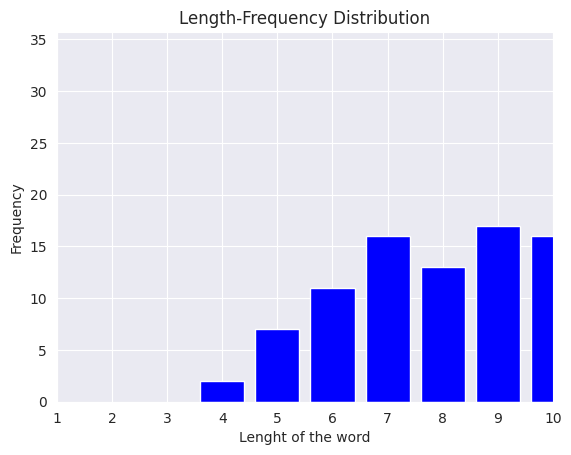

Maximum Length of a comment: 123
Minimum Length of a comment: 4
Average Length of a comment: 21.0


In [221]:
frequency = dict()
for i in dataset.length:
    frequency[i] = frequency.get(i, 0)+1

plt.bar(frequency.keys(), frequency.values(), color ="blue")
plt.xlim(1, 10)

plt.xlabel('Lenght of the word')
plt.ylabel('Frequency')
plt.title('Length-Frequency Distribution')
plt.show()
print(f"Maximum Length of a comment: {max(dataset.length)}")
print(f"Minimum Length of a comment: {min(dataset.length)}")
print(f"Average Length of a comment: {round(np.mean(dataset.length),0)}")

In [222]:
# data summary

def data_summary(df):

    reviews = []
    words = []
    u_words = []
    total_u_words = [word.strip().lower() for t in list(df.cleaned) for word in t.strip().split()]
    class_label= [k for k,v in df.Label.value_counts().to_dict().items()]
  # find word list
    for label in class_label:
        word_list = [word.strip().lower() for t in list(df[df.Label==label].cleaned) for word in t.strip().split()]
        counts = dict()
        for word in word_list:
                counts[word] = counts.get(word, 0)+1
        # sort the dictionary of word list
        ordered = sorted(counts.items(), key= lambda item: item[1],reverse = True)
        # reviewss per class
        reviews.append(len(list(df[df.Label==label].cleaned)))
        # Total Word per class
        words.append(len(word_list))
        # Unique words per class
        u_words.append(len(np.unique(word_list)))

        print("\nClass Name : ",label)
        print("Number of Comments:{}".format(len(list(df[df.Label==label].cleaned))))
        print("Number of Words:{}".format(len(word_list)))
        print("Number of Unique Words:{}".format(len(np.unique(word_list))))
        print("Most Frequent Words:\n")
        for k,v in ordered[:10]:
              print("{}\t{}".format(k,v))
    print("Total Number of Unique Words:{}".format(len(np.unique(total_u_words))))

    return reviews,words,u_words,class_label

#call the fucntion
reviews,words,u_words,class_names = data_summary(df)


Class Name :  Fraud
Number of Comments:260
Number of Words:5529
Number of Unique Words:1186
Most Frequent Words:

আমার	325
টাকা	321
থেকে	151
বিকাশ	123
নিয়ে	109
গেছে	101
করে	91
বলে	85
এর	81
আমি	79

Class Name :  Partial Fraud
Number of Comments:260
Number of Words:5624
Number of Unique Words:1222
Most Frequent Words:

আমার	306
টাকা	284
আমি	149
থেকে	134
করে	102
বিকাশ	97
গেছে	91
ভাই	79
হাজার	78
নিয়ে	75
Total Number of Unique Words:1807


In [223]:
data_matrix = pd.DataFrame({'Total comments':reviews,
                            'Total Words':words,
                            'Unique Words':u_words,
                            'Class Names':class_names})
data = pd.melt(data_matrix, id_vars="Class Names", var_name="Category", value_name="Values")

In [224]:
data

,Class Names,Category,Values
0,Fraud,Total comments,260
1,Partial Fraud,Total comments,260
2,Fraud,Total Words,5529
3,Partial Fraud,Total Words,5624
4,Fraud,Unique Words,1186
5,Partial Fraud,Unique Words,1222


# Label Encoding Function

In [225]:
from sklearn.preprocessing import LabelEncoder

def label_encoding(Label,bool):
    le = LabelEncoder()
    le.fit(Label)
    encoded_labels = le.transform(Label)
    labels = np.array(encoded_labels)
    class_names =le.classes_
    if bool == True:
        print("\n\t\t\t===== Label Encoding =====","\nClass Names:-->",le.classes_)
        for i in sample_data:
            print(Label[i],' ', encoded_labels[i],'\n')

    return labels

In [226]:
class_names

['Fraud', 'Partial Fraud']

# Dataset Splitting Function

In [227]:
def dataset_split(feature_space,Label):
    """
    This function will return the splitted (80%-20%) feature vector .
    """

    X_train,X_test,y_train,y_test = train_test_split(feature_space,Label,train_size = 0.9,
                                                  test_size = 0.1,random_state =0)
    print("Feature Size :======>",X_train.shape[1])
    print("\nDataset Distribution:\n")
    print("\tSet Name","\t\tSize")
    print("\t========\t\t======")

    print("\tFull\t\t\t",feature_space.shape[0],
        "\n\tTraining\t\t",X_train.shape[0],
        "\n\tTest\t\t\t",X_test.shape[0])

    return X_train,X_test,y_train,y_test

In [228]:
df.cleaned = df.stemming.apply(lambda x:x.replace('\n',' '))

In [229]:
df.head(3)

,Label,cleaned,stemming
0,Fraud,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...,জব এর কথা বলে আম থেক ১২০০ টাকা নিয় ৫০০ টাকা ই...
1,Fraud,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...,বৃত্তির কথা বলে আম থেক আজ ৩৫০০০ হাজা টাকা নিয়ে...
2,Fraud,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...,ভাই আম পরিচি এক জন মহিলা বিকাশ ভেরিফা কোট টি ব...


In [230]:
max_fatures = 500
tokenizer = Tokenizer(num_words=max_fatures, split=' ')
tokenizer.fit_on_texts(df['stemming'].values)
X = tokenizer.texts_to_sequences(df['stemming'].values)
X = pad_sequences(X)

In [231]:
X

array([[  0,   0,   0, ..., 299,   2,  26],
       [  0,   0,   0, ...,  88,  19, 363],
       [  0,   0,   0, ...,  44,  21,  16],
       ...,
       [  0,   0,   0, ...,   6, 468, 131],
       [  0,   0,   0, ...,   6,  14, 268],
       [  0,   0,   0, ...,   2, 121, 237]], dtype=int32)

In [232]:
np.shape(X)

(520, 102)

# LSTM Model

In [233]:
embed_dim = 64
model = Sequential()
model.add(Embedding(max_fatures, embed_dim,input_length = X.shape[1]))
#model.add(SpatialDropout1D(0.4))
model.add(LSTM(64, dropout=0.2, recurrent_dropout=0.2))
model.add(Dense(2,activation='softmax'))
model.compile(loss = 'categorical_crossentropy', optimizer='adam', metrics=['accuracy'])
model.summary()

Model: "sequential_5"
_________________________________________________________________
 Layer (type)                Output Shape              Param #   
 embedding_5 (Embedding)     (None, 102, 64)           32000     
                                                                 
 lstm_5 (LSTM)               (None, 64)                33024     
                                                                 
 dense_5 (Dense)             (None, 2)                 130       
                                                                 
Total params: 65,154
Trainable params: 65,154
Non-trainable params: 0
_________________________________________________________________


In [234]:
Y = pd.get_dummies(df['Label']).values
X_train, X_test, Y_train, Y_test = train_test_split(X,Y, test_size = 0.20,random_state = 42)
print(X_train.shape,Y_train.shape)
print(X_test.shape,Y_test.shape)

(416, 102) (416, 2)
(104, 102) (104, 2)


In [235]:
history=model.fit(X_train, Y_train, epochs = 50, batch_size=32, verbose = 1,validation_data=(X_test,Y_test))

Epoch 1/50
13/13 [==============================] - 5s 168ms/step - loss: 0.6887 - accuracy: 0.5769 - val_loss: 0.6819 - val_accuracy: 0.6154
Epoch 2/50
13/13 [==============================] - 2s 190ms/step - loss: 0.6622 - accuracy: 0.6611 - val_loss: 0.6671 - val_accuracy: 0.6058
Epoch 3/50
13/13 [==============================] - 4s 278ms/step - loss: 0.5999 - accuracy: 0.7524 - val_loss: 0.6202 - val_accuracy: 0.6442
Epoch 4/50
13/13 [==============================] - 5s 363ms/step - loss: 0.5400 - accuracy: 0.7788 - val_loss: 0.6006 - val_accuracy: 0.6635
Epoch 5/50
13/13 [==============================] - 4s 291ms/step - loss: 0.4604 - accuracy: 0.8029 - val_loss: 0.6335 - val_accuracy: 0.6250
Epoch 6/50
13/13 [==============================] - 3s 258ms/step - loss: 0.3945 - accuracy: 0.8438 - val_loss: 0.6245 - val_accuracy: 0.6731
Epoch 7/50
13/13 [==============================] - 3s 244ms/step - loss: 0.3236 - accuracy: 0.8558 - val_loss: 0.6609 - val_accuracy: 0.7212
Epoch 

In [236]:
import tensorflow as tf

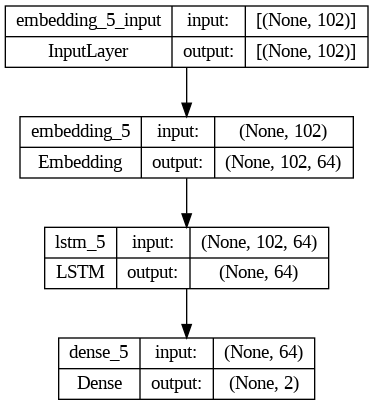

In [237]:
tf.keras.utils.plot_model(model, show_shapes=True)

In [238]:
score = model.evaluate(X_train, Y_train,batch_size=64, verbose=2)
print('Train loss:', score[0])
print('Train accuracy:', score[1])

7/7 - 0s - loss: 0.0643 - accuracy: 0.9615 - 234ms/epoch - 33ms/step
Train loss: 0.06425552815198898
Train accuracy: 0.9615384340286255


In [239]:
score = model.evaluate(X_test, Y_test,batch_size=64, verbose=2)
print('Test loss:', score[0])
acc=score[1]
print('Test accuracy:', acc)

2/2 - 0s - loss: 1.3826 - accuracy: 0.6923 - 70ms/epoch - 35ms/step
Test loss: 1.3825792074203491
Test accuracy: 0.692307710647583


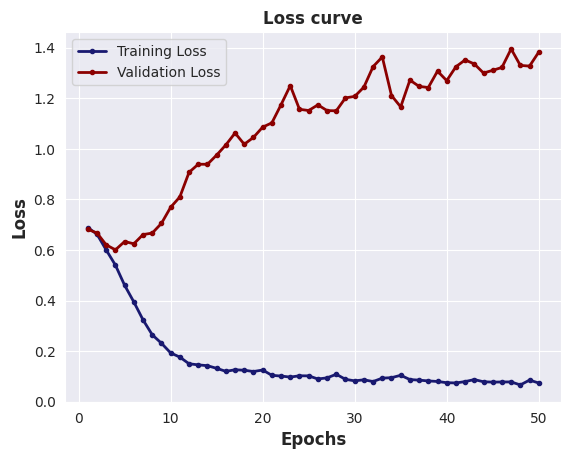

In [240]:
loss_values = history.history['loss']
val_loss_values = history.history['val_loss']
acc = history.history['accuracy']
val_acc = history.history['val_accuracy']
epochs = range(1, len(acc) + 1)
sns.set_style('darkgrid')

plt.plot(epochs, loss_values, color='midnightblue', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.plot(epochs, val_loss_values, color='darkred', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.title('Loss curve',fontsize=12,fontweight='bold')
plt.xlabel('Epochs',fontsize=12,fontweight='bold')
plt.ylabel('Loss',fontsize=12,fontweight='bold')
plt.legend(['Training Loss','Validation Loss'])


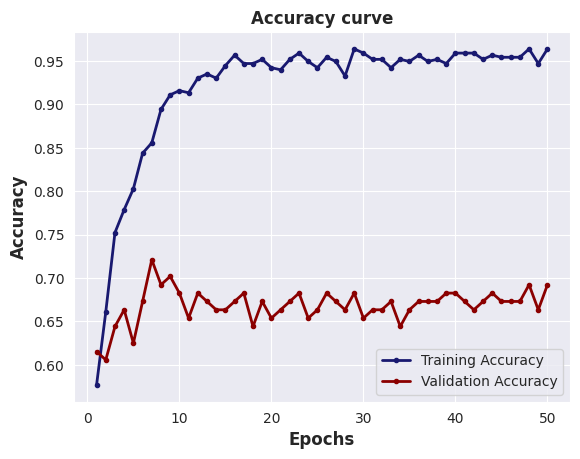

In [241]:
                  #=========================================================
                  ############### Epochs vs Validation Accuracy Plot ##########
                  #==========================================================

plt.plot(epochs, acc, color='midnightblue', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.plot(epochs, val_acc, color='darkred', linewidth = 2,
          marker='o', markersize=3,label='Training Accuracy')
plt.title('Accuracy curve',fontsize=12,fontweight='bold')
plt.xlabel('Epochs',fontsize=12,fontweight='bold')
plt.ylabel('Accuracy',fontsize=12,fontweight='bold')
plt.legend(['Training Accuracy','Validation Accuracy'])

In [242]:
X_train.shape,Y_train.shape,X_test.shape,Y_test.shape

((416, 102), (416, 2), (104, 102), (104, 2))

In [243]:
y_pred=model.predict(X_test)
y_pred=np.argmax(y_pred, axis=1)
y_test=np.argmax(Y_test, axis=1)
cm = confusion_matrix(y_test, y_pred)
print(cm)

4/4 [==============================] - 0s 19ms/step
[[31 19]
 [13 41]]


In [244]:
from sklearn.metrics import classification_report
report = pd.DataFrame(classification_report(y_test, y_pred,output_dict=True)).transpose()

report = report.rename(index={'0': 'Fraud','1':'Partial Fraud'})
report[['precision','recall','f1-score']]=report[['precision','recall','f1-score']].apply(lambda x: round(x*100,2))

report

,precision,recall,f1-score,support
Fraud,70.45,62.00,65.96,50.000000
Partial Fraud,68.33,75.93,71.93,54.000000
accuracy,69.23,69.23,69.23,0.692308
macro avg,69.39,68.96,68.94,104.000000
weighted avg,69.35,69.23,69.06,104.000000


4/4 [==============================] - 0s 21ms/step


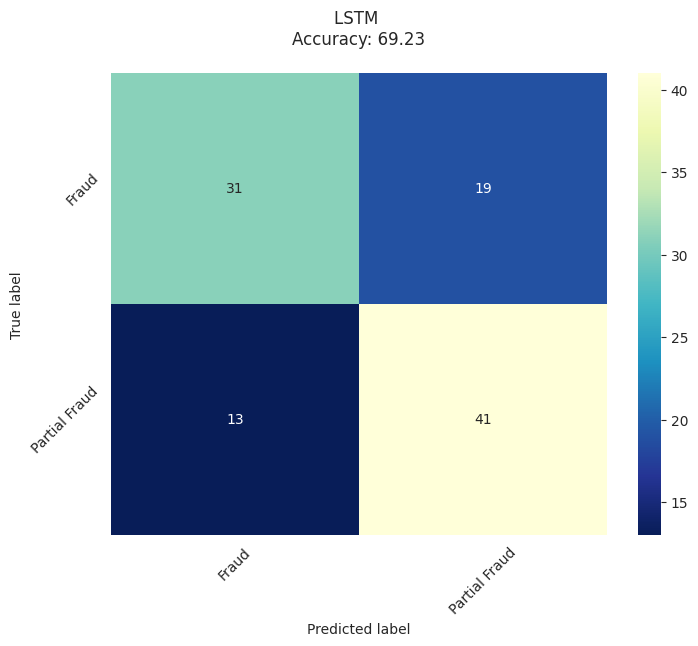

In [245]:
from sklearn.metrics import classification_report, confusion_matrix
from sklearn.metrics import accuracy_score,precision_score,recall_score,f1_score,roc_auc_score
predictions = model.predict(X_test)
y_pred = np.argmax(predictions, axis=1)

cm = confusion_matrix(y_test, y_pred)

class_names = ['Fraud', 'Partial Fraud']
# Transform to df for easier plotting
cm_df = pd.DataFrame(cm,index = class_names, columns = class_names)

plt.figure(figsize=(8,6))
sns.heatmap(cm_df, annot=True,cmap="YlGnBu_r", fmt='g')
plt.title('LSTM \nAccuracy: {0:.2f}\n'.format(accuracy_score(y_test, y_pred)*100))
plt.ylabel('True label')
plt.xlabel('Predicted label')
plt.xticks(rotation = 45)
plt.yticks(rotation = 45)
plt.show()

In [246]:
twt = ['জব এর কথা বলে আমার থেকে ১২০০ টাকা নিয়েছে। ৫০০ টাকা ইনভেস্ট এর কথা বলে ১২০০ টাকা নিলো প্রতারক।']
#vectorizing the tweet by the pre-fitted tokenizer instance
twt = tokenizer.texts_to_sequences(twt)
#padding the tweet to have exactly the same shape as `embedding_2` input
twt = pad_sequences(twt, maxlen=28, dtype='int32', value=0)
sentiment = model.predict(twt,batch_size=1,verbose = 2)[0]
if(np.argmax(sentiment) == 0):
    print("Fraud")
elif (np.argmax(sentiment) == 1):
    print("Partial Fraud")

1/1 - 0s - 244ms/epoch - 244ms/step
Fraud
